# EDA combined: solar generation and radiation

**Step 3 of the EDA guide:** the relationship between our target and the explanatory data. Both sources were studied separately first:
`../energy_charts/energy_charts_eda.ipynb` (target) and `../meteoswiss/meteoswiss_eda.ipynb` (weather). The decisions from their decision logs are applied here.

| | |
|---|---|
| Solar | Energy-Charts (Fraunhofer ISE), Swiss solar generation, CC BY 4.0, attribution "energy-charts.info" |
| Radiation | MeteoSwiss, global radiation, mean of Luzern, Mosen, Schüpfheim, Egolzwil; Pilatus separately. CC BY 4.0, "Source: MeteoSwiss" |
| Period | 2019–2025, hourly, fixed CET (UTC+1), every stamp marks the start of the hour |
| Installed capacity | SFOE plant register (`../bfe_register/bfe_register_eda.ipynb`), scaled to the official capacity from Energy-Charts; from Q6 on |
| Forecasts | Open-Meteo Previous Runs API, ICON-D2 (`../open_meteo/open_meteo_eda.ipynb`), 2024–2025, CC BY 4.0, attribution "Open-Meteo.com"; from Q6 on |

**How this notebook works:** every section starts with a **question**, then the code, a chart, and a note **Finding → Consequence**.
*Prepared with AI assistance (Claude); findings to be questioned and checked by us.*

In [1]:
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

TZ = "Etc/GMT-1"   # fixed CET = UTC+1, no clock changes (the minus sign is correct for this name)
FIG = Path("../../figures/eda")
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"


def save(fig, name):
    fig.savefig(FIG / f"combined_{name}.png", dpi=160, bbox_inches="tight")

## Load and clean, applying the decision logs of both notebooks

In [2]:
def load_solar():
    frames = []
    for f in sorted(Path("../energy_charts/data").glob("public_power_ch_*.json")):
        d = json.loads(f.read_text(encoding="utf-8"))
        data = next(p["data"] for p in d["production_types"] if p["name"] == "Solar")
        frames.append(pd.Series(data, index=pd.to_datetime(d["unix_seconds"], unit="s", utc=True), dtype="float64"))
    s = pd.concat(frames)
    return s[~s.index.duplicated()].sort_index().tz_convert(TZ)


def load_radiation(abbr):
    files = sorted(Path("../meteoswiss/data").glob(f"ogd-smn_{abbr}_h_*.csv"))
    d = pd.concat(pd.read_csv(f, sep=";", encoding="cp1252", usecols=["reference_timestamp", "gre000h0"]) for f in files)
    d["time"] = pd.to_datetime(d["reference_timestamp"], format="%d.%m.%Y %H:%M", utc=True).dt.tz_convert(TZ) - pd.Timedelta(hours=1)
    return d.drop_duplicates("time", keep="last").set_index("time")["gre000h0"]


solar_raw = load_solar()
daily_raw = solar_raw.resample("D").sum() / 1000
typical = daily_raw.rolling(15, center=True, min_periods=7).median()
flagged = daily_raw[daily_raw < 0.10 * typical].loc["2019":"2025"].index
flagged = flagged.drop(pd.Timestamp("2024-11-22", tz=TZ))      # real: 36 cm of snow (Energy-Charts notebook, Q5b)

solar = solar_raw.loc["2019":"2025"].copy()
solar[solar.index.normalize().isin(flagged)] = np.nan          # suspicious days become missing
night = solar.index.hour.isin([22, 23, 0, 1, 2, 3])
solar[night & (solar > 100)] = np.nan                          # the two 415 MW values in September 2022

stations = {a: load_radiation(a.lower()).reindex(solar.index) for a in ["LUZ", "MOA", "SPF", "EGO", "PIL"]}
radiation = pd.DataFrame(stations)
radiation[night] = 0                                           # sensor offsets at night (MeteoSwiss notebook, Q7)
sun = radiation[["LUZ", "MOA", "SPF", "EGO"]].mean(axis=1)     # the "radiation average"

data = pd.DataFrame({"solar_MW": solar, "sun_W_m2": sun, "sun_LUZ": radiation["LUZ"], "pilatus": radiation["PIL"]})
print("Hours:", len(data), "| days set to missing:", len(flagged), "| empty solar hours:", data["solar_MW"].isna().sum(), "| empty radiation hours:", data["sun_W_m2"].isna().sum())

# Daily values. Solar is divided by its annual mean, a simple way to remove the growth of the fleet for now.
# Flurin's register will replace this with the proper capacity factor (generation / installed capacity).
daily = pd.DataFrame({
    "solar_GWh": data["solar_MW"].resample("D").sum(min_count=20) / 1000,
    "sun": data["sun_W_m2"].resample("D").sum(min_count=20) / 1000,
    "sun_LUZ": data["sun_LUZ"].resample("D").sum(min_count=20) / 1000,
    "pilatus": data["pilatus"].resample("D").sum(min_count=20) / 1000,
})
daily["solar_rel"] = daily["solar_GWh"] / daily["solar_GWh"].groupby(daily.index.year).transform("mean")
daily.head()

Hours: 61368 | days set to missing: 11 | empty solar hours: 266 | empty radiation hours: 0


,solar_GWh,sun,sun_LUZ,pilatus,solar_rel
2019-01-01 00:00:00+01:00,1.0144,0.78250,0.643,1.969,0.164905
2019-01-02 00:00:00+01:00,1.4284,0.79275,0.832,0.566,0.232206
2019-01-03 00:00:00+01:00,2.3936,1.64850,1.658,1.911,0.389113
2019-01-04 00:00:00+01:00,2.8799,1.67925,1.725,1.911,0.468168
2019-01-05 00:00:00+01:00,0.3428,0.38500,0.309,0.498,0.055727


## Q1: Radiation average and reported solar GW on top of each other. Do they move together?

Same weeks in two years side by side. Both curves are divided by their highest value in the panel, so they share one scale; the real highest values are written in each panel.

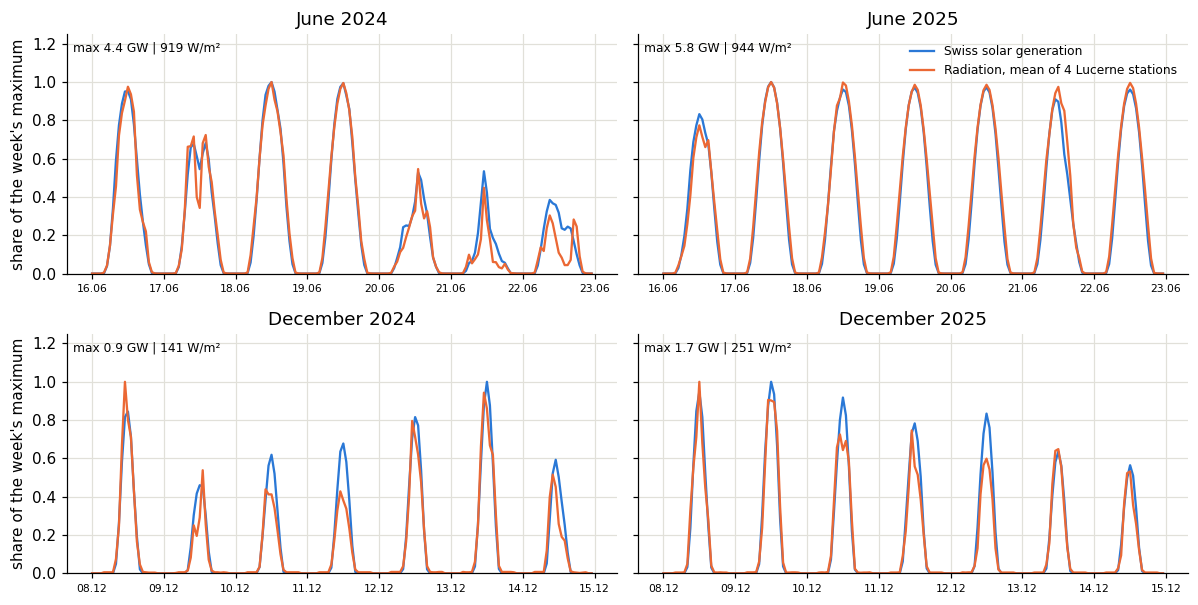

In [3]:
weeks = [("06-16", "06-22", "June"), ("12-08", "12-14", "December")]
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharey=True)
for row, (a, b, label) in enumerate(weeks):
    for col, year in enumerate([2024, 2025]):
        ax = axes[row, col]
        w = data.loc[f"{year}-{a}":f"{year}-{b}"]
        ax.plot(w.index, w["solar_MW"] / w["solar_MW"].max(), color=BLUE, label="Swiss solar generation")
        ax.plot(w.index, w["sun_W_m2"] / w["sun_W_m2"].max(), color=ORANGE, label="Radiation, mean of 4 Lucerne stations")
        ax.set_title(f"{label} {year}")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m", tz=TZ))
        ax.tick_params(axis="x", labelsize=7)
        ax.text(0.01, 0.97, f"max {w['solar_MW'].max() / 1000:.1f} GW | {w['sun_W_m2'].max():.0f} W/m²", transform=ax.transAxes, va="top", fontsize=8)
        ax.set_ylim(0, 1.25)
    axes[row, 0].set_ylabel("share of the week's maximum")
axes[0, 1].legend(frameon=False, fontsize=8, loc="upper right")
plt.tight_layout()
save(fig, "overlay_weeks")
plt.show()

> **Finding:** the two curves follow each other almost hour by hour, in summer and in winter, including cloudy days (e.g. 20–22 June 2024). The match is less tight in December. The highest solar value also grows much faster than the radiation (June: 4.4 → 5.8 GW with 919 → 944 W/m²).
> **Consequence:** the Lucerne radiation average is a good explanatory variable for Swiss solar generation. The growth of the fleet must be separated from the weather, which is what the installed capacity from the SFOE register (Flurin) is for.

## Q2: And over a whole year?

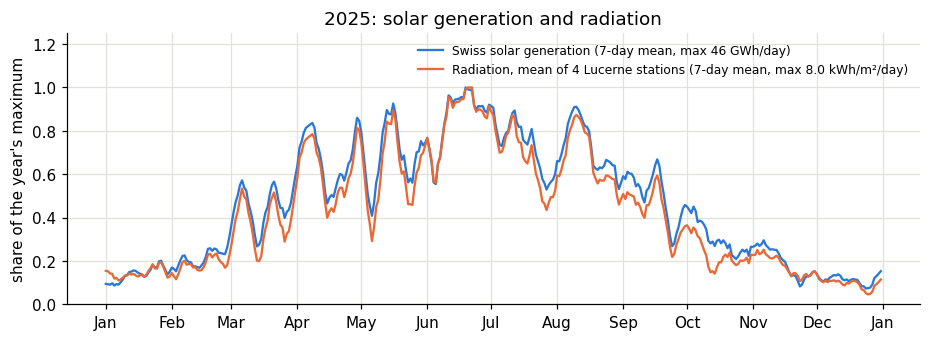

Daily Pearson r in 2025: 0.985


In [4]:
year = daily.loc["2025"]
smooth = year[["solar_GWh", "sun"]].rolling(7, center=True, min_periods=4).mean()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(smooth.index, smooth["solar_GWh"] / smooth["solar_GWh"].max(), color=BLUE, label=f"Swiss solar generation (7-day mean, max {smooth['solar_GWh'].max():.0f} GWh/day)")
ax.plot(smooth.index, smooth["sun"] / smooth["sun"].max(), color=ORANGE, label=f"Radiation, mean of 4 Lucerne stations (7-day mean, max {smooth['sun'].max():.1f} kWh/m²/day)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b", tz=TZ))
ax.xaxis.set_major_locator(mdates.MonthLocator(tz=TZ))
ax.set_ylim(0, 1.25)
ax.set_ylabel("share of the year's maximum")
ax.set_title("2025: solar generation and radiation")
ax.legend(frameon=False, fontsize=8, loc="upper right")
save(fig, "overlay_2025")
plt.show()
print("Daily Pearson r in 2025:", round(year["solar_GWh"].corr(year["sun"]), 3))

> **Finding:** over the year both curves have the same shape (daily Pearson r = 0.985 in 2025). In spring and autumn solar stays a little above the radiation.
> **Consequence:** one linear scale between radiation and solar does not fit all seasons equally. **To question:** is this because tilted panels catch the low sun better? The register has the tilt; the fleet's growth during the year may also play a part.

## Q3: Do the time stamps of both sources line up?

In [5]:
pair = data[["solar_MW", "sun_W_m2"]].dropna()
lags = {k: round(pair["solar_MW"].corr(pair["sun_W_m2"].shift(k)), 3) for k in range(-3, 4)}
pd.Series(lags, name="Pearson r, hourly").rename_axis("radiation shifted by hours").to_frame().T

radiation shifted by hours,-3,-2,-1,0,1,2,3
"Pearson r, hourly",0.564,0.717,0.822,0.86,0.82,0.712,0.559


> **Finding:** the correlation is highest with **no shift** and falls off evenly on both sides, so the time stamps are aligned after our conversion (fixed CET, MeteoSwiss −1 h). The level of r here (0.86) is lower than in Q4 because these are raw MW, which include the fleet's growth.
> **Consequence:** the alignment is confirmed, and the combined dataset can use these time stamps.

## Q4: How strong is the relationship? By season, and with one station or four?

Hourly Pearson r, all year, mean of 4 stations: 0.977 | Luzern only: 0.955
Daily Pearson r per year: {2019: 0.973, 2020: 0.985, 2021: 0.969, 2022: 0.982, 2023: 0.978, 2024: 0.976, 2025: 0.985}


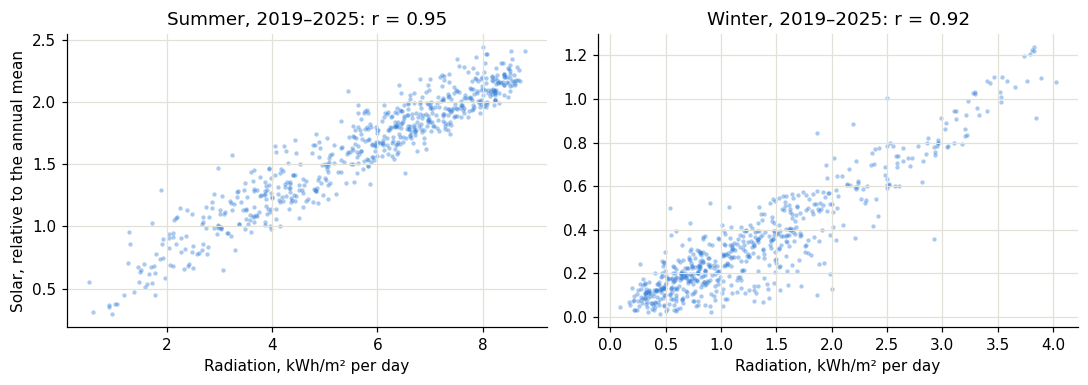

,"daily r, mean of 4 stations","daily r, Luzern only"
season,,
winter,0.916,0.889
spring,0.958,0.926
summer,0.950,0.922
autumn,0.968,0.940
all year,0.973,0.956


In [6]:
season_of = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
             6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
d = daily.dropna(subset=["solar_rel", "sun", "sun_LUZ"]).copy()
d["season"] = d.index.month.map(season_of)
strength = pd.DataFrame({
    "daily r, mean of 4 stations": d.groupby("season").apply(lambda t: t["solar_rel"].corr(t["sun"]), include_groups=False),
    "daily r, Luzern only": d.groupby("season").apply(lambda t: t["solar_rel"].corr(t["sun_LUZ"]), include_groups=False),
}).reindex(["winter", "spring", "summer", "autumn"])
strength.loc["all year"] = [d["solar_rel"].corr(d["sun"]), d["solar_rel"].corr(d["sun_LUZ"])]
strength = strength.round(3)

h = data.dropna(subset=["solar_MW", "sun_W_m2"]).copy()
h["solar_rel"] = h["solar_MW"] / h["solar_MW"].groupby(h.index.year).transform("mean")
print("Hourly Pearson r, all year, mean of 4 stations:", round(h["solar_rel"].corr(h["sun_W_m2"]), 3), "| Luzern only:", round(h["solar_rel"].corr(h["sun_LUZ"]), 3))
print("Daily Pearson r per year:", d.groupby(d.index.year).apply(lambda t: round(t["solar_GWh"].corr(t["sun"]), 3), include_groups=False).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, s in zip(axes, ["summer", "winter"]):
    t = d[d["season"] == s]
    ax.scatter(t["sun"], t["solar_rel"], s=8, color=BLUE, alpha=0.4, linewidths=0)
    ax.set_title(f"{s.capitalize()}, 2019–2025: r = {strength.loc[s, 'daily r, mean of 4 stations']:.2f}")
    ax.set_xlabel("Radiation, kWh/m² per day")
axes[0].set_ylabel("Solar, relative to the annual mean")
plt.tight_layout()
save(fig, "scatter_summer_winter")
plt.show()
strength

> **Finding:** this is the first answer to G2. Solar follows the radiation strongly: daily Pearson r = 0.973 over the year and 0.92–0.97 within each season, so the relationship is not just the shared seasons. Winter is the weakest (0.916), which the scatter shows as a wider cloud. The **mean of four stations beats Luzern alone in every season**, by 0.02–0.03.
> **Consequence:** use the four-station mean. *These r values compare Swiss solar with Lucerne weather, using solar relative to its annual mean; they are to be repeated with the capacity factor from the register.*

## Q5: Why is winter weaker? Does fog explain it?

Share of fog days: 15 %
Solar compared with the Lucerne-based fit (median): {'other days': 0.99, 'fog days': 1.27}
R² October to February, Lucerne radiation only: 0.851 | with Pilatus as well: 0.867


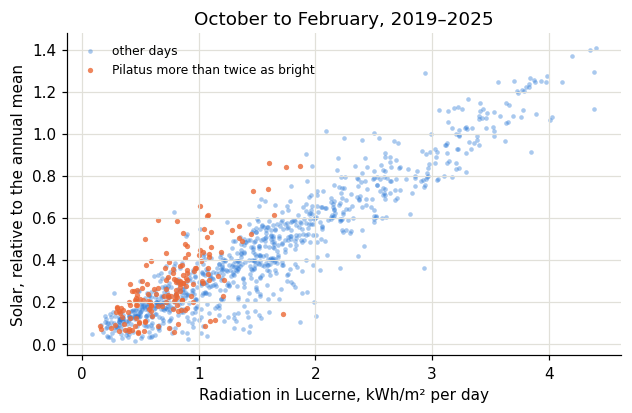

In [7]:
w = d[d.index.month.isin([10, 11, 12, 1, 2])].dropna(subset=["pilatus"]).copy()
w["fog"] = (w["pilatus"] > 2 * w["sun"]) & (w["pilatus"] >= 1.5)   # same definition as in the MeteoSwiss notebook, Q11

fit = sm.OLS(w["solar_rel"], sm.add_constant(w[["sun"]])).fit()
fit2 = sm.OLS(w["solar_rel"], sm.add_constant(w[["sun", "pilatus"]])).fit()
w["expected"] = fit.predict()
above = (w["solar_rel"] / w["expected"]).groupby(w["fog"]).median()
print(f"Share of fog days: {w['fog'].mean() * 100:.0f} %")
print("Solar compared with the Lucerne-based fit (median):", {("fog days" if k else "other days"): round(v, 2) for k, v in above.items()})
print("R² October to February, Lucerne radiation only:", round(fit.rsquared, 3), "| with Pilatus as well:", round(fit2.rsquared, 3))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.scatter(w.loc[~w["fog"], "sun"], w.loc[~w["fog"], "solar_rel"], s=9, color=BLUE, alpha=0.4, linewidths=0, label="other days")
ax.scatter(w.loc[w["fog"], "sun"], w.loc[w["fog"], "solar_rel"], s=12, color=ORANGE, alpha=0.8, linewidths=0, label="Pilatus more than twice as bright")
ax.set_xlabel("Radiation in Lucerne, kWh/m² per day")
ax.set_ylabel("Solar, relative to the annual mean")
ax.set_title("October to February, 2019–2025")
ax.legend(frameon=False, fontsize=8)
save(fig, "winter_fog")
plt.show()

> **Finding:** on the 15 % of winter days with much more radiation on Pilatus, Swiss solar is about **27 % higher** than the Lucerne radiation suggests (median; other days: 1 % lower). Many panels are probably above the fog or low cloud, or simply elsewhere in Switzerland. Adding Pilatus raises R² only slightly, from 0.85 to 0.87 (same data, not a forecast test).
> **Consequence:** fog explains part of the weak winter, but not all of it; the spread remains on other days too. Whether Pilatus is worth including is decided when modelling, on a held-out period. Snow on panels is another possible cause (see 22.11.2024).

# Adding the plant register and the forecasts

From here on the notebook uses **all sources**. The register and the forecasts were studied separately first: `../bfe_register/bfe_register_eda.ipynb` and `../open_meteo/open_meteo_eda.ipynb`. The decisions from their decision logs are applied here, in the same way as above.

Before running: `python download_data.py` in `../energy_charts`, `../meteoswiss`, `../bfe_register` and `../open_meteo`.

## Load and clean, applying the decision logs of the register and the forecasts

In [8]:
# SFOE register: PV plants; a plant counts from its start date on
plants = pd.read_csv("../bfe_register/data/ElectricityProductionPlant.csv", dtype=str)
plants = plants[plants["SubCategory"] == "subcat_2"].copy()
for column in ["TotalPower", "_x", "_y"]:
    plants[column] = pd.to_numeric(plants[column], errors="coerce")
plants["start"] = pd.to_datetime(plants["BeginningOfOperation"])
lucerne = plants[plants["Canton"] == "LU"]


def capacity_per_day(p):
    s = p.groupby(p["start"].dt.floor("D"))["TotalPower"].sum().cumsum() / 1000
    days = pd.date_range("2018-12-31", "2025-12-31", freq="D")
    return s.reindex(s.index.union(days)).ffill().reindex(days)


capacity = pd.DataFrame({"CH_register_MW": capacity_per_day(plants), "LU_register_MW": capacity_per_day(lucerne)})

# Official capacity at each year end (Energy-Charts); the factor between it and the register is interpolated over the days
installed = json.loads(Path("../bfe_register/data/installed_power_ch_yearly.json").read_text(encoding="utf-8"))
official = pd.Series(next(p["data"] for p in installed["production_types"] if p["name"] == "Solar DC"),
                     index=[int(y) for y in installed["time"]]) * 1000
ends = pd.DatetimeIndex([f"{y}-12-31" for y in range(2018, 2026)])
scale = pd.Series(official.loc[2018:2025].values / capacity["CH_register_MW"].reindex(ends).values, index=ends)
scale = scale.reindex(capacity.index).interpolate()
capacity["CH_MW"] = capacity["CH_register_MW"] * scale
capacity["LU_MW"] = capacity["LU_register_MW"] * scale

# Weights of the stations: the capacity that is closest to each of them
meta = pd.read_csv("../bfe_register/data/ogd-smn_meta_stations.csv", sep=";", encoding="cp1252").set_index("station_abbr")
points = meta.loc[["LUZ", "EGO", "MOA", "SPF"], ["station_coordinates_lv95_east", "station_coordinates_lv95_north"]]
located = lucerne.dropna(subset=["_x", "_y"])
distance = pd.DataFrame({s: np.hypot(located["_x"] - points.loc[s].iloc[0], located["_y"] - points.loc[s].iloc[1]) for s in points.index})
weights = located.groupby(distance.idxmin(axis=1))["TotalPower"].sum() / located["TotalPower"].sum()
print("Capacity weights of the stations:", weights.round(3).to_dict())


# Forecasts: only radiation is a mean of the preceding hour, so only radiation moves one hour earlier
def load_forecast(location):
    h = json.loads(sorted(Path("../open_meteo/data").glob(f"previous_day1_{location}_*.json"))[0].read_text(encoding="utf-8"))["hourly"]
    index = pd.DatetimeIndex(pd.to_datetime(h["time"], utc=True)).tz_convert(TZ)
    d = pd.DataFrame({k.replace("_previous_day1", ""): v for k, v in h.items() if k != "time"}, index=index)
    d["shortwave_radiation_icon_d2"] = d["shortwave_radiation_icon_d2"].shift(-1)
    return d


forecasts = {location: load_forecast(location) for location in weights.index}


# Further MeteoSwiss columns, loaded like the radiation above
def load_weather(abbr, column):
    files = sorted(Path("../meteoswiss/data").glob(f"ogd-smn_{abbr}_h_*.csv"))
    d = pd.concat(pd.read_csv(f, sep=";", encoding="cp1252", usecols=["reference_timestamp", column]) for f in files)
    d["time"] = pd.to_datetime(d["reference_timestamp"], format="%d.%m.%Y %H:%M", utc=True).dt.tz_convert(TZ) - pd.Timedelta(hours=1)
    return d.drop_duplicates("time", keep="last").set_index("time")[column].reindex(solar.index)


Capacity weights of the stations: {'EGO': 0.386, 'LUZ': 0.378, 'MOA': 0.152, 'SPF': 0.084}


In [9]:
# One table with all sources, one row per hour
table = pd.DataFrame({"solar_MW": solar, "radiation_mean": sun})
available = radiation[weights.index]
table["radiation_weighted"] = (available * weights).sum(axis=1, min_count=1) / available.notna().mul(weights).sum(axis=1)
for station in ["LUZ", "EGO", "MOA", "SPF", "PIL"]:
    table[f"radiation_{station}"] = radiation[station]
table["temperature_LUZ"] = load_weather("luz", "tre200h0")
table["sunshine_LUZ"] = load_weather("luz", "sre000h0")
table["snow_depth_LUZ"] = load_weather("luz", "htoauths")
table["snow_depth_SPF"] = load_weather("spf", "htoauths")

forecast_radiation = pd.DataFrame({k: v["shortwave_radiation_icon_d2"] for k, v in forecasts.items()}).reindex(solar.index)
table["forecast_radiation"] = (forecast_radiation * weights).sum(axis=1, min_count=4)
table["forecast_temperature"] = forecasts["LUZ"]["temperature_2m_icon_d2"].reindex(solar.index)
table["forecast_cloud"] = forecasts["LUZ"]["cloud_cover_icon_d2"].reindex(solar.index)

day = table.index.tz_localize(None).normalize()
for column in ["CH_register_MW", "LU_register_MW", "CH_MW", "LU_MW"]:
    table[f"capacity_{column}"] = capacity[column].reindex(day).values
table["capacity_factor"] = table["solar_MW"] / table["capacity_CH_MW"]
table["lucerne_estimate_MW"] = table["capacity_factor"] * table["capacity_LU_MW"]
print(table.shape)
table.loc["2025-06-15 11:00":"2025-06-15 13:00"].T.round(2)


(61368, 21)


,2025-06-15 11:00:00+01:00,2025-06-15 12:00:00+01:00,2025-06-15 13:00:00+01:00
solar_MW,4608.80,4837.70,4034.70
radiation_mean,891.00,910.50,890.75
radiation_weighted,898.71,907.40,885.45
radiation_LUZ,912.00,915.00,876.00
radiation_EGO,899.00,898.00,888.00
radiation_MOA,878.00,901.00,889.00
radiation_SPF,875.00,928.00,910.00
radiation_PIL,952.00,789.00,614.00
temperature_LUZ,25.50,26.80,28.00
sunshine_LUZ,60.00,60.00,60.00



> **Finding:** one table with **61,368 hours** and all sources on one time axis. Cleaning as above: 11 error days and 2 impossible hours are empty, night radiation is 0. The stations can now be weighted by the capacity closest to them: Egolzwil 39 %, Luzern 38 %, Mosen 15 %, Schüpfheim 8 %. The radiation forecast uses the same weights; Pilatus has no weight, as it is a mountain and not a place with solar plants.
> **Consequence:** `table` replaces `data` from here on. Only `previous_day1` columns are forecasts, the rest is measured.


## Q6: Which capacity is right? Capacity factor with the register or with the official capacity

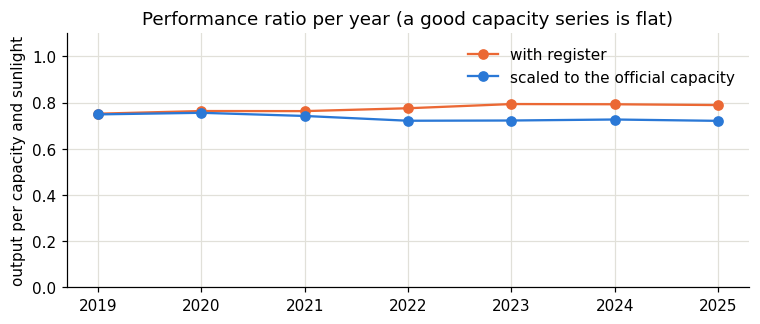

Capacity factor: mean 0.106 | highest 0.71


,2019,2020,2021,2022,2023,2024,2025
with register,0.752,0.763,0.763,0.775,0.793,0.792,0.789
scaled to official,0.749,0.755,0.742,0.721,0.722,0.726,0.721


In [10]:
# Output per unit of capacity and sunlight, per year. The weather is removed, so a good capacity gives nearly the same value every year.
with_solar = table.dropna(subset=["solar_MW"])
by_year = with_solar.groupby(with_solar.index.year)
ratio = pd.DataFrame({
    "with register": by_year["solar_MW"].mean() / by_year["capacity_CH_register_MW"].mean() / by_year["radiation_weighted"].mean() * 1000,
    "scaled to official": by_year["solar_MW"].mean() / by_year["capacity_CH_MW"].mean() / by_year["radiation_weighted"].mean() * 1000,
})
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ratio.index, ratio["with register"], color=ORANGE, marker="o", label="with register")
ax.plot(ratio.index, ratio["scaled to official"], color=BLUE, marker="o", label="scaled to the official capacity")
ax.set_ylim(0, 1.1)
ax.set_ylabel("output per capacity and sunlight")
ax.set_title("Performance ratio per year (a good capacity series is flat)")
ax.legend(frameon=False)
save(fig, "performance_ratio")
plt.show()
print("Capacity factor: mean", round(table["capacity_factor"].mean(), 3), "| highest", round(table["capacity_factor"].max(), 3))
ratio.round(3).T



> **Finding:** with the register, the output per unit of capacity and sunlight **rises by 5 %** (0.75 to 0.79), with most of the step in 2022–2023. Solar modules do not improve with age, so this is an **artefact** of the growing gap in the register (`bfe_register_eda.ipynb`, Q4). Scaled to the official capacity it **falls by 4 %** (0.75 to 0.72), which fits the growing share of flat and east/west roofs. Neither line is perfectly flat.
> **Consequence:** we use the **scaled capacity** for the capacity factor (`capacity_CH_MW`). The share of Lucerne still comes from the register, assuming the gap is the same in Lucerne as in Switzerland. The mean capacity factor is 10.6 %, the highest hour 71 %.
> **To question:** the official capacity is DC. The Energy-Charts generation is scaled to the official statistics, so this check is not fully independent.


## Q7: How strong is the relationship with the capacity factor? (G2)
Q4 used solar relative to its annual mean. Here it is repeated with the capacity factor, and with the stations weighted by capacity.

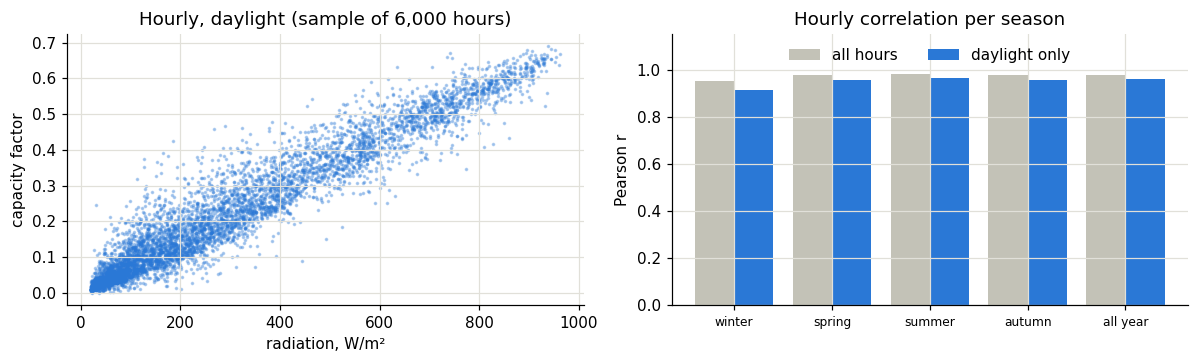

,"hourly r, weighted","hourly r, daylight only","daily r, weighted","daily r, mean of 4 stations","daily r, Luzern only"
winter,0.952,0.912,0.923,0.925,0.898
spring,0.977,0.956,0.964,0.965,0.932
summer,0.980,0.963,0.968,0.970,0.937
autumn,0.976,0.954,0.972,0.975,0.946
all year,0.978,0.960,0.977,0.978,0.960


In [11]:
rows = {}
seasons = {"winter": [12, 1, 2], "spring": [3, 4, 5], "summer": [6, 7, 8], "autumn": [9, 10, 11], "all year": list(range(1, 13))}
hours = table.dropna(subset=["capacity_factor", "radiation_weighted"])
for name, months in seasons.items():
    t = hours[hours.index.month.isin(months)]
    light = t[t["radiation_weighted"] > 20]
    days = t.resample("D")[["capacity_factor", "radiation_weighted", "radiation_mean", "radiation_LUZ"]].mean().dropna()
    rows[name] = {"hourly r, weighted": t["capacity_factor"].corr(t["radiation_weighted"]),
                  "hourly r, daylight only": light["capacity_factor"].corr(light["radiation_weighted"]),
                  "daily r, weighted": days["capacity_factor"].corr(days["radiation_weighted"]),
                  "daily r, mean of 4 stations": days["capacity_factor"].corr(days["radiation_mean"]),
                  "daily r, Luzern only": days["capacity_factor"].corr(days["radiation_LUZ"])}
goal2 = pd.DataFrame(rows).T

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
sample = hours[hours["radiation_weighted"] > 20].sample(6000, random_state=1)
axes[0].scatter(sample["radiation_weighted"], sample["capacity_factor"], s=2, alpha=0.3, color=BLUE)
axes[0].set_xlabel("radiation, W/m²")
axes[0].set_ylabel("capacity factor")
axes[0].set_title("Hourly, daylight (sample of 6,000 hours)")
x = np.arange(len(goal2))
axes[1].bar(x - 0.2, goal2["hourly r, weighted"], width=0.4, color=GREY, label="all hours")
axes[1].bar(x + 0.2, goal2["hourly r, daylight only"], width=0.4, color=BLUE, label="daylight only")
axes[1].set_xticks(x, goal2.index, fontsize=8)
axes[1].set_ylim(0, 1.15)
axes[1].set_ylabel("Pearson r")
axes[1].set_title("Hourly correlation per season")
axes[1].legend(frameon=False, loc="upper center", ncol=2)
plt.tight_layout()
save(fig, "correlation_per_season")
plt.show()
goal2.round(3)



> **Finding (G2):** with the capacity factor the result of Q4 holds and gets slightly stronger: r = **0.98** per hour and per day over the year, 0.95 and 0.92 in winter. The night helps: in daylight alone r is 0.91 (winter) to 0.96 (summer). Winter stays the weakest season. **Weighting the stations by capacity does not help here:** the simple mean of Q4 is just as good, even very slightly better (daily 0.978 vs. 0.977). Both beat Luzern alone (0.960).
> **Consequence:** G2 is reached. We report all hours, as stated in the goal, and daylight only, which is the fairer number. For the **national** target we keep the simple mean. The weighted mean is only meant for estimates of **Lucerne**.


## Q8: Is snow on the panels the other cause of the weak winter?
Q5 left this open. The snow sensors only start in November 2023, so we also look for days with far less output than the sunlight explains.

In [12]:
# The snow sensor: is it usable? Values above 5 cm while warmer than 15 degrees cannot be snow
for station, column in [("LUZ", "snow_depth_LUZ"), ("SPF", "snow_depth_SPF")]:
    wrong = table[(table[column] > 5) & (table["temperature_LUZ"] > 15)]
    print(f"{station}: first value {table[column].first_valid_index().date()}, hours above 5 cm at more than 15 C: {len(wrong)}, months {sorted(set(wrong.index.month))}")
table.loc[table.index.month.isin([5, 6, 7, 8, 9]), ["snow_depth_LUZ", "snow_depth_SPF"]] = np.nan

per_day = table.resample("D").agg({"solar_MW": lambda s: s.sum(min_count=20), "capacity_CH_MW": "mean", "radiation_weighted": "mean",
                                   "temperature_LUZ": "mean", "snow_depth_LUZ": "max", "snow_depth_SPF": "max"})
output_per_sun = per_day["solar_MW"] / (per_day["capacity_CH_MW"] * per_day["radiation_weighted"])
per_day["share_of_expected"] = output_per_sun / output_per_sun.rolling(31, center=True, min_periods=10).median()
per_day["sun_kWh_m2"] = per_day["radiation_weighted"] * 24 / 1000
low = per_day[(per_day["share_of_expected"] < 0.35) & (per_day["sun_kWh_m2"] > 0.3)]
print(f"\nDays below 35 % of the expected output: {len(low)}")
print("Per month:", low.groupby(low.index.month).size().to_dict())
print(f"Mean temperature on these days: {low['temperature_LUZ'].mean():.1f} C | all days Dec-Feb: {per_day[per_day.index.month.isin([12, 1, 2])]['temperature_LUZ'].mean():.1f} C")
sensor = low[low.index >= "2023-12-01"]
print(f"Days since December 2023: {len(sensor)}, with more than 2 cm of snow at Luzern or Schüpfheim: {((sensor['snow_depth_LUZ'] > 2) | (sensor['snow_depth_SPF'] > 2)).sum()}")
lost = (low["solar_MW"] / low["share_of_expected"] - low["solar_MW"]).sum() / 1000
winter_energy = per_day[per_day.index.month.isin([11, 12, 1, 2])]["solar_MW"].sum() / 1000
print(f"Estimated lost generation: {lost:.0f} GWh, {lost / winter_energy * 100:.1f} % of the energy in November to February")

table["is_snow_cover_day"] = pd.DatetimeIndex(day).isin(low.index.tz_localize(None))
table["is_data_error_day"] = pd.DatetimeIndex(day).isin(flagged.tz_localize(None))
low.assign(snow_LUZ=low["snow_depth_LUZ"], snow_SPF=low["snow_depth_SPF"])[["sun_kWh_m2", "share_of_expected", "temperature_LUZ", "snow_LUZ", "snow_SPF"]].round(2)


LUZ: first value 2023-11-29, hours above 5 cm at more than 15 C: 2, months [6, 9]
SPF: first value 2023-11-24, hours above 5 cm at more than 15 C: 47, months [5, 6, 7]



Days below 35 % of the expected output: 25
Per month: {1: 8, 2: 1, 11: 3, 12: 13}
Mean temperature on these days: -0.3 C | all days Dec-Feb: 3.0 C
Days since December 2023: 9, with more than 2 cm of snow at Luzern or Schüpfheim: 9
Estimated lost generation: 60 GWh, 1.7 % of the energy in November to February


,sun_kWh_m2,share_of_expected,temperature_LUZ,snow_LUZ,snow_SPF
2019-01-10 00:00:00+01:00,0.87,0.24,-0.50,NaN,NaN
2019-01-11 00:00:00+01:00,1.25,0.24,-0.62,NaN,NaN
2019-01-12 00:00:00+01:00,0.87,0.25,1.18,NaN,NaN
2019-12-31 00:00:00+01:00,0.88,0.28,0.63,NaN,NaN
2020-02-27 00:00:00+01:00,1.23,0.32,2.59,NaN,NaN
2021-01-06 00:00:00+01:00,0.78,0.34,-0.34,NaN,NaN
2021-01-17 00:00:00+01:00,0.61,0.34,0.32,NaN,NaN
2021-01-25 00:00:00+01:00,1.54,0.25,0.71,NaN,NaN
2021-12-10 00:00:00+01:00,0.48,0.14,0.32,NaN,NaN
2022-12-09 00:00:00+01:00,0.55,0.24,0.91,NaN,NaN



> **Finding (answer to Q5):**
> - The snow sensors start only in November 2023, and they are **wrong in summer**: «snow» of more than 5 cm at more than 15 °C, nearly all at Schüpfheim. Set to NaN from May to September.
> - **25 days** are below 35 % of the output that the sunlight explains, all from November to February, on average at −0.3 °C (mean of December to February: 3.0 °C), in connected periods. On **all 9** days since December 2023 there was snow at Luzern or Schüpfheim. 22.11.2024, kept by the Energy-Charts notebook, is one of them (up to 39 cm in Luzern that day).
>
> **Consequence:** these days are **snow on the panels (characteristic), not errors**. They stay in the data and are flagged as `is_snow_cover_day`, which gives a snow indicator for all of 2019–2025. Estimated loss: about 60 GWh, 1.7 % of the energy from November to February: small over the winter, large on single days.
> **To question:** the threshold of 35 % is our choice, and it compares national output with Lucerne weather. Before December 2023 we cannot confirm single days.


## Q9: How good is the forecast compared with measured radiation?

2025, Pearson r: hourly 0.967, daily 0.973
Forecast / measured, October to February: fog days 1.86 (42 days), other days 1.03


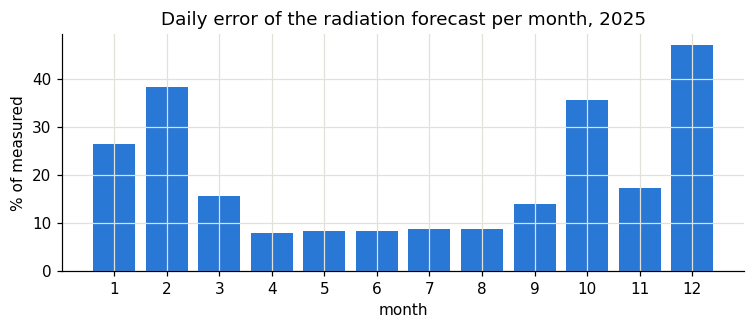

In [13]:
both = table[["forecast_radiation", "radiation_weighted", "radiation_PIL"]].dropna().loc["2025"]
days = both.resample("D").mean() * 24 / 1000
foggy = days["radiation_PIL"] > 2 * days["radiation_weighted"]
foggy = foggy & (days["radiation_PIL"] >= 1.5)                                # same definition as in Q5
winter_days = days[days.index.month.isin([10, 11, 12, 1, 2])]
print(f"2025, Pearson r: hourly {both['forecast_radiation'].corr(both['radiation_weighted']):.3f}, daily {days['forecast_radiation'].corr(days['radiation_weighted']):.3f}")
print(f"Forecast / measured, October to February: fog days {winter_days.loc[foggy, 'forecast_radiation'].mean() / winter_days.loc[foggy, 'radiation_weighted'].mean():.2f}"
      f" ({foggy.loc[winter_days.index].sum()} days), other days {winter_days.loc[~foggy, 'forecast_radiation'].mean() / winter_days.loc[~foggy, 'radiation_weighted'].mean():.2f}")
errors = (days["forecast_radiation"] - days["radiation_weighted"]).abs().groupby(days.index.month).mean() / days["radiation_weighted"].groupby(days.index.month).mean() * 100
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.bar(errors.index, errors.values, color=BLUE)
ax.set_xticks(range(1, 13))
ax.set_xlabel("month")
ax.set_ylabel("% of measured")
ax.set_title("Daily error of the radiation forecast per month, 2025")
save(fig, "forecast_error_per_month")
plt.show()



> **Finding:** the forecast of the day before is close to the measured radiation in 2025 (r = 0.97 per hour and per day), and on normal winter days it is right on average (ratio 1.03). **On fog days it is 86 % too high** (ratio 1.86, 42 days). The daily error is about 9 % from April to August, but 36 % in October, 47 % in December, 27 % in January and 38 % in February.
> **Consequence:** the forecast is a good input for G3, but it does not see fog. This is the main weakness in the season that matters most. We report errors per season.


## Q10: Many variables at once. Which are redundant, and which leak?

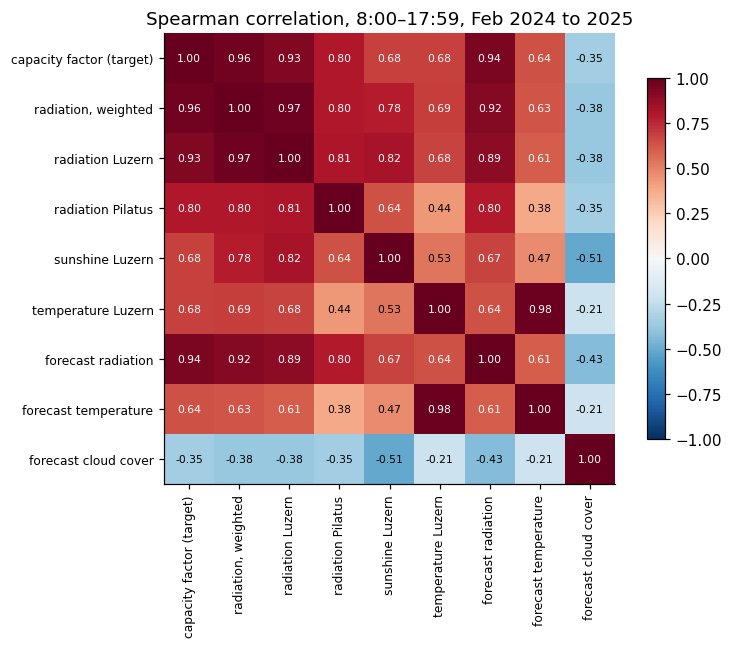

,capacity factor (target),"radiation, weighted",radiation Luzern,radiation Pilatus,sunshine Luzern,temperature Luzern,forecast radiation,forecast temperature,forecast cloud cover
Spearman with the capacity factor,1.0,0.96,0.93,0.8,0.68,0.68,0.94,0.64,-0.35


In [14]:
columns = {"capacity_factor": "capacity factor (target)", "radiation_weighted": "radiation, weighted", "radiation_LUZ": "radiation Luzern",
           "radiation_PIL": "radiation Pilatus", "sunshine_LUZ": "sunshine Luzern", "temperature_LUZ": "temperature Luzern",
           "forecast_radiation": "forecast radiation", "forecast_temperature": "forecast temperature", "forecast_cloud": "forecast cloud cover"}
corr = table.loc["2024-02":"2025", list(columns)].rename(columns=columns)
corr = corr[corr.index.hour.isin(range(8, 18))].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax.grid(False)
ax.set_title("Spearman correlation, 8:00–17:59, Feb 2024 to 2025")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
save(fig, "correlation_heatmap")
plt.show()
corr.iloc[0].round(2).rename("Spearman with the capacity factor").to_frame().T



> **Finding:** the target goes with the weighted radiation (ρ = 0.96), the forecast radiation (0.94) and Luzern (0.93). **Redundant:** radiation weighted vs. Luzern (0.97), temperature forecast vs. measured (0.98). Sunshine (0.68) says less than radiation. Temperature (0.68) is mostly the **season**, not a cause: warm hours are bright hours. Cloud cover says little (−0.35).
> **Leakage check:** measured weather of the target hour, `solar_MW`, `capacity_factor`, `lucerne_estimate_MW` and `is_snow_cover_day` are **not known the day before**. Only `forecast_*`, past values of the target, the calendar and the capacity of the previous day are allowed.
> **Consequence:** first inputs for SARIMAX: `forecast_radiation`, possibly `forecast_temperature`.


## Q11: Is the dataset complete? (G1)

In [15]:
checks = {
    "Solar": table["solar_MW"].notna(),
    "Radiation, weighted": table["radiation_weighted"].notna(),
    "Radiation, all 5 stations": table[[f"radiation_{s}" for s in ["LUZ", "EGO", "MOA", "SPF", "PIL"]]].notna().all(axis=1),
    "Temperature Luzern": table["temperature_LUZ"].notna(),
    "Capacity CH + LU": table["capacity_CH_MW"].notna() & table["capacity_LU_MW"].notna(),
}
coverage = pd.DataFrame({name: flag.groupby(flag.index.year).mean() * 100 for name, flag in checks.items()}).T
coverage["2019-2025"] = pd.Series({name: flag.mean() * 100 for name, flag in checks.items()})
needed = checks["Solar"] & checks["Radiation, weighted"] & checks["Temperature Luzern"] & checks["Capacity CH + LU"]
print(f"Hours 2019-2025: {len(table):,} | complete after cleaning: {needed.sum():,} = {needed.mean() * 100:.2f} %")
print("Forecast 2025:", round(table.loc["2025", "forecast_radiation"].notna().mean() * 100, 2), "%")
coverage.round(2)


Hours 2019-2025: 61,368 | complete after cleaning: 61,102 = 99.57 %
Forecast 2025: 100.0 %


,2019,2020,2021,2022,2023,2024,2025,2019-2025
Solar,96.99,100.0,100.0,99.98,100.0,100.00,100.00,99.57
"Radiation, weighted",100.00,100.0,100.0,100.00,100.0,100.00,100.00,100.00
"Radiation, all 5 stations",100.00,100.0,100.0,100.00,100.0,99.12,99.46,99.80
Temperature Luzern,100.00,100.0,100.0,100.00,100.0,100.00,100.00,100.00
Capacity CH + LU,100.00,100.0,100.0,100.00,100.0,100.00,100.00,100.00



> **Finding (G1):** **99.57 %** of the 61,368 hours are complete after cleaning (266 hours missing: the 11 error days and 2 impossible hours). Requirement: ≥ 99 %. The forecast is complete for 2025. Forecasts do not exist before 19.1.2024.
> **Consequence:** G1 is reached. Nothing was filled.


## Q12: Baseline. What must the G3 forecast beat?

In [16]:
test = table.loc["2025"].dropna(subset=["capacity_factor"])
train = table.loc["2019":"2024"].dropna(subset=["capacity_factor", "radiation_weighted"])
last_year = table.loc["2024-02":"2024"].dropna(subset=["capacity_factor", "forecast_radiation"])

# monthly factor: capacity factor per unit of radiation, learned before the test year
measured_factor = train["capacity_factor"].groupby(train.index.month).sum() / train["radiation_weighted"].groupby(train.index.month).sum()
forecast_factor = last_year["capacity_factor"].groupby(last_year.index.month).sum() / last_year["forecast_radiation"].groupby(last_year.index.month).sum()

predictions = {
    "constant: mean of 2019-2024": pd.Series(train["capacity_factor"].mean(), index=test.index),
    "same hour of the previous day": table["capacity_factor"].shift(24).reindex(test.index),
    "radiation forecast x monthly factor (from measured 2019-2024)": test["forecast_radiation"] * test.index.month.map(measured_factor),
    "radiation forecast x monthly factor (from forecast 2024)": test["forecast_radiation"] * test.index.month.map(forecast_factor),
    "for comparison, NOT allowed: measured radiation x monthly factor": test["radiation_weighted"] * test.index.month.map(measured_factor),
}
truth = test["capacity_factor"]
rows = {}
for name, p in predictions.items():
    ok = p.notna()
    in_winter = ok & test.index.month.isin([11, 12, 1, 2])
    in_summer = ok & test.index.month.isin([5, 6, 7, 8])
    rows[name] = {"MAE hourly, %": (p[ok] - truth[ok]).abs().mean() / truth[ok].mean() * 100,
                  "MAE daily, %": (p.resample("D").mean() - truth.resample("D").mean()).abs().mean() / truth.resample("D").mean().mean() * 100,
                  "RMSE hourly, %": np.sqrt(((p[ok] - truth[ok]) ** 2).mean()) / truth[ok].mean() * 100,
                  "MAE hourly, Nov-Feb, %": (p[in_winter] - truth[in_winter]).abs().mean() / truth[in_winter].mean() * 100,
                  "MAE hourly, May-Aug, %": (p[in_summer] - truth[in_summer]).abs().mean() / truth[in_summer].mean() * 100}
print("Errors in % of the mean capacity factor of the same hours, test year 2025")
pd.DataFrame(rows).T.round(1)


Errors in % of the mean capacity factor of the same hours, test year 2025


,"MAE hourly, %","MAE daily, %","RMSE hourly, %","MAE hourly, Nov-Feb, %","MAE hourly, May-Aug, %"
constant: mean of 2019-2024,123.9,57.5,157.3,253.8,98.5
same hour of the previous day,27.6,25.1,61.3,37.9,24.9
radiation forecast x monthly factor (from measured 2019-2024),16.3,11.9,33.5,28.7,14.2
radiation forecast x monthly factor (from forecast 2024),17.4,13.9,34.1,28.0,15.5
"for comparison, NOT allowed: measured radiation x monthly factor",16.0,11.3,30.7,24.7,14.1



> **Finding (G3, test year 2025, capacity factor):**
> - A constant is off by 124 %, "same hour as yesterday" by **27.6 %**.
> - The **simple baseline** of G3, radiation forecast × monthly factor, is off by **16.3 %** per hour and 11.9 % per day.
> - In the same simple way, even the **measured** radiation only reaches 16.0 %, and this version is not allowed in a forecast.
>
> **Consequence:** the target of G3 is **MAE ≤ 14.7 %** (at least 10 % below 16.3 %). That is better than what perfect knowledge of the Lucerne radiation reaches with the simple method, so a better weather forecast alone will not do it. SARIMAX has to gain from the time structure (hour of the day, autocorrelation of the error). G3 is **ambitious but open**. In winter the error stays near 30 %.


## Save the table with all sources

In [17]:
# second Lucerne estimate: local weather instead of the national curve
table["lucerne_estimate_weather_MW"] = table["radiation_weighted"] * table.index.month.map(measured_factor) * table["capacity_LU_MW"]
out = Path("../../data/processed")
out.mkdir(parents=True, exist_ok=True)
table.index.name = "time_local"
table.to_csv(out / "hourly_dataset.csv")
print(table.shape)
print(list(table.columns))


(61368, 24)
['solar_MW', 'radiation_mean', 'radiation_weighted', 'radiation_LUZ', 'radiation_EGO', 'radiation_MOA', 'radiation_SPF', 'radiation_PIL', 'temperature_LUZ', 'sunshine_LUZ', 'snow_depth_LUZ', 'snow_depth_SPF', 'forecast_radiation', 'forecast_temperature', 'forecast_cloud', 'capacity_CH_register_MW', 'capacity_LU_register_MW', 'capacity_CH_MW', 'capacity_LU_MW', 'capacity_factor', 'lucerne_estimate_MW', 'is_snow_cover_day', 'is_data_error_day', 'lucerne_estimate_weather_MW']


# Summary

| # | Finding | Consequence |
|---|---|---|
| Q1, Q2 | Radiation and solar move together almost hour by hour | radiation is the right explanatory variable |
| Q2 | Solar slightly above radiation in spring and autumn | to question: tilt of the panels? |
| Q3 | Time stamps aligned, highest correlation at no shift | conversion confirmed |
| Q4 | Daily r = 0.973; 0.92–0.97 per season; winter weakest | four-station mean instead of Luzern alone |
| Q5 | About 27 % more solar than expected on fog days | Pilatus as a candidate input, to be tested on held-out data |

## Is the data suitable? (Insights)

**Yes for G2:** the weather explains most of the day-to-day changes in solar generation. **Two limits remain:** this compares *national* solar with *Lucerne* weather, so it says nothing yet about Lucerne's own output; and it uses *measured* weather, which is not available for a real forecast.

## Open questions (to discuss)

1. Is the Lucerne radiation average good enough for national solar, or do we need stations from other regions as well?
2. Is fixed CET what was meant by "European time"?

## Next steps

- The 3 slides, and the README sections for Deliverable 3.


## Summary with the register and the forecasts

| # | Finding | Consequence |
|---|---|---|
| Q6 | Register rises by 5 %, scaled capacity falls by 4 % in output per sunlight | use the scaled capacity for the capacity factor |
| Q7 | r = 0.98 per hour and per day; in daylight 0.91–0.96 per season | G2 reached; simple mean for the national target |
| Q8 | 25 winter days far below the expected output | snow on the panels, kept and flagged |
| Q9 | Forecast r = 0.97, but 86 % too high on fog days | good input, fog stays the weakness |
| Q10 | Radiation and forecast go with the target, temperature mostly with the season | only `forecast_*` and past values as inputs |
| Q11 | 99.57 % of the hours complete | G1 reached |
| Q12 | Same hour as yesterday 27.6 %, simple baseline 16.3 % | target of G3: MAE ≤ 14.7 % |

## Decision log of this part

| Source | Issue | Error or characteristic? | Decision | Affected |
|---|---|---|---|---|
| Register | Only about 91 % of the official capacity from 2022 on | **error** of coverage | scaled to the official capacity per year | 2022–2025 |
| Register | Later extensions dated back, removed plants missing, 2026 incomplete | characteristic | limitation; no capacity after 2025 | – |
| Open-Meteo | Radiation is the mean of the preceding hour, UTC | characteristic | fixed CET, radiation −1 h; temperature and cloud cover not shifted | all |
| Open-Meteo | ICON-D2 starts on 19.1.2024, ICON-CH2 in July 2025 | characteristic | use ICON-D2; not filled | – |
| Open-Meteo | Forecast about 2 times too high on fog days | characteristic of the model | kept, errors reported per season | fog days |
| Energy-Charts | 25 winter days far below the expected output | characteristic (snow on panels) | kept, `is_snow_cover_day` | 25 days |
| MeteoSwiss | «Snow» in summer, mainly Schüpfheim | **error** | snow NaN from May to September | about 50 hours |
| All | Measured values unknown the day before | leakage risk | only `forecast_*` and past values as inputs | – |

## For the README

**Data Quality**

1. **Missingness with causes:** 99.57 % of the hours are complete. Gaps have causes: sensors that did not exist yet (snow depth only from November 2023), forecast models that started late (ICON-D2 in January 2024) and short station outages at Mosen. Nothing was filled.
2. **Disguised missing values:** zeros in the solar series on days with sunlight (11 days in 2019, 2018 even more), and a night offset at Egolzwil. Real zeros also exist: snow on the panels.
3. **Consistency checks:** annual solar sums match the official statistics exactly. Hourly radiation matches the daily MeteoSwiss values. The register matches the official capacity until 2020, and from 2022 on only about 91 %. Shortwave = direct + diffuse.
4. **Decision log:** see the tables above and in the notebooks of the sources.

**Insights**

5. **Is the data suitable? Yes for G1 and G2, partly for G3.** The forecasts cover the test year and beat all simple predictions, but only one earlier forecast year exists, and the model does not see fog.
6. **Leakage check:** see Q10.
7. **Baseline (test year 2025):** constant 124 %, same hour yesterday 27.6 %, radiation forecast × monthly factor 16.3 %.

## Answer per goal

| Goal | Status | Evidence | Remaining risk |
|---|---|---|---|
| G1 cleaned dataset | **reached** | `data/processed/hourly_dataset.csv`, 99.57 % | level of the capacity |
| G2 solar follows the weather | **reached** | Q4, Q5, Q7, Q8 | national target vs. Lucerne weather |
| G3 day-ahead forecast | **open** | baseline 16.3 %, target ≤ 14.7 % | ambitious, winter errors, one forecast year for training |

## Limitations

- The target is national and its hourly shape is an extrapolation; the weather is from stations in and near Canton Lucerne.
- The capacity is a snapshot of plants in operation, scaled to the official capacity. The scaling assumes that the gap in the register is the same in Lucerne.
- Forecasts exist only for 2024–2025, not for the whole period 2019–2025.
- The Lucerne estimate is checked with data that may not be published, so that check is not part of this repository.

## Further open questions

1. **Pronovo in the README:** may we report the result of that check in one sentence? The question to the coach from 21 October is still open, so this notebook contains no number from it.
2. **G3 and fog:** should the forecast contain a fog signal known in advance, e.g. Pilatus of the previous day?
3. **Lucerne estimate:** `lucerne_estimate_MW` (national curve) or `lucerne_estimate_weather_MW` (Lucerne radiation × monthly factor)? Both are in the dataset.
4. **Is r ≥ 0.95 over all hours a meaningful target for G3,** given that the night alone makes r high?
